# 005. Testing PyPL, and comparing potential fits and vibrational overlap methods

This notebook shows how to check that PyPL works, and how to compare the different ways of fitting the potential energy
surfaces (PES) of a 1D configurational coordinate diagram (1D CCD) and of computing its Franck-Condon integrals and
vibrational overlap function (VOF). There are three layers of checks:

| layer | what it is | how to run it | time |
| --- | --- | --- | --- |
| **test suite** `tests/` | unit and regression tests of the package (pytest); includes the guarantee that tutorials 001 and 002 give the original results | `pytest` | ~1 min |
| **validation checks** | 81 physics and regression checks of the 1D CCD path on NV$^-$ in diamond and in MgO | `python validation/check_1d_ccd.py` | ~15 s |
| **validation suite** `validation/` | scripts that compare every VOF method and every fit, with figures, tables and an `index.md` per run | `python validation/compare_vof.py`, `plot_ccd_wavefunctions.py`, `vof_report.py`, `run_all.py` | 30 s to 20 min |

Sections 1-2 run the first two. Sections 3-4 do method and fit comparisons directly in Python, with the package API, so
you can adapt them to your own system. Section 5 runs the validation scripts. The physics of each method is explained in
`validation/METHODS.md`.

## 0. Setup

In [1]:
import os
import subprocess
import sys
import tempfile
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
from PIL import Image as PILImage

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

# The validation scripts write to validation/outputs/ by default. Send this notebook's runs to a temporary directory
# instead, so running it never touches existing results.
OUTPUTS = tempfile.mkdtemp(prefix="pypl_tutorial_005_")
ENV = dict(os.environ, PYPL_VALIDATION_OUTPUT_ROOT=OUTPUTS, PYTHONIOENCODING="utf-8")


def run(args, tail=12):
    # Run a command from the repository root with this kernel's Python and print the last lines of its output.
    start = time.time()
    proc = subprocess.run([sys.executable] + args, cwd=REPO_ROOT, env=ENV, capture_output=True, text=True, encoding="utf-8")
    text = (proc.stdout + proc.stderr).replace(OUTPUTS, "<tmp>").replace(os.path.relpath(OUTPUTS, REPO_ROOT), "<tmp>")
    lines = text.rstrip().splitlines()
    print("$ python %s   (exit %d, %.0f s)" % (" ".join(args), proc.returncode, time.time() - start))
    print("\n".join(lines[-tail:]))
    return proc


def show(path, width=1300):
    # Display a figure, downscaled and palette-compressed so that the notebook stays small.
    import io as _io

    img = PILImage.open(path).convert("RGB")
    if img.width > width:
        img = img.resize((width, round(img.height * width / img.width)), PILImage.LANCZOS)
    buf = _io.BytesIO()
    img.quantize(colors=256, method=PILImage.Quantize.MEDIANCUT).save(buf, format="png", optimize=True)
    display(Image(data=buf.getvalue(), width=820))


print("validation outputs of this notebook go to a temporary directory, shown as <tmp> below")

validation outputs of this notebook go to a temporary directory, shown as <tmp> below


## 1. The test suite

`pytest` collects the tests in `tests/` (configured in `pyproject.toml`). They need the test extras,
`pip install ".[test]"`. The files:

| file | what it checks |
| --- | --- |
| `test_legacy_tutorials.py` | reruns the computations of tutorials 001 and 002 (35 arrays: Huang-Rhys factors, spectral densities, lineshapes, spectra, Franck-Condon matrices) and compares them with `tests/data/legacy_reference.npz`, which was generated from the **original** PyPL code; also the numbers printed in the two notebooks |
| `test_config_coord_1d_solver.py` | the Ruhoff solver: closure, identity at $\Delta Q = 0$, symmetry, populations, convergence, spectra |
| `test_config_coord_1d_vof_solver.py` | the extended solver changes nothing it inherits (bit for bit); harmonic functions; Hermite, finite-difference and cubic routes against each other; line positions from levels |
| `test_config_coord_1d_potential.py` | every fit and spline option, invalid options, smooth tails |
| `test_isc.py`, `test_nv_mgo.py` | the ISC rate and units; the WEST parser, the MgO CCD and the numbers of tutorial 003 |

`-m "not slow"` skips the end-to-end check of tutorial 003 (about 15 s); `pytest` alone runs everything.

In [2]:
proc = run(["-m", "pytest", "-q", "--color=no", "-m", "not slow", "-p", "no:cacheprovider"], tail=1)

$ python -m pytest -q --color=no -m not slow -p no:cacheprovider   (exit 0, 45 s)
107 passed, 1 deselected in 43.56s


A failure in `test_legacy_tutorials.py` means the behaviour of the original API changed. The reference must **not** be
regenerated to make it pass; it is rebuilt only from the original code, with
`python tests/tools/make_legacy_reference.py --pypl-root <checkout of the original code>`.

## 2. The validation checks

`check_1d_ccd.py` prints one line per group and a summary; `-v` lists every check. It exits with 0 only if all pass, so it
can gate a script or CI job (the CI runs it after `pytest`).

In [3]:
proc = run(["validation/check_1d_ccd.py"], tail=3)

$ python validation/check_1d_ccd.py   (exit 0, 20 s)
Large Huang-Rhys factors and the NV- in MgO dataset

81/81 checks passed.


## 3. Comparing VOF methods

`config_coord_1d_vof_solver` gives four routes to the Franck-Condon matrix $F_{ij}$; each fills `fc_ints`, so the same
`bulid_fc_lsp` builds the VOF from any of them:

| method | call | potential |
| --- | --- | --- |
| Ruhoff recurrences (PyPL) | `compute_franck_condon_integrals(ni, nf)` | harmonic |
| Hermite quadrature | `compute_franck_condon_integrals_hermite(ni, nf)` | harmonic |
| finite differences | `compute_franck_condon_integrals_fd(ni, nf, V_i, V_f, q_i, q_f)` | any callable $V(Q)$ |
| cubic perturbation theory | `compute_franck_condon_integrals_cubic(ni, nf, b_i, b_f, q_i, q_f)` | harmonic + $bQ^3$ (Tutorial 004) |

On the same parabolas, the first three solve the same problem in independent ways, so they must agree: this is the
like-for-like test of the solver. We use the NV$^-$ center in diamond of Tutorial 002 (emission, 50 ES $\times$ 60 GS levels).

In [4]:
from pypl.config_coord_1d_potential import config_coord_1d_potential
from pypl.config_coord_1d_vof_solver import config_coord_1d_vof_solver
from pypl.utils import parse_atoms_qexml, parse_total_energy_qexml

data = "002_nv_diamond_1d_ccd"
mass_list = {"C": 12.0107, "N": 14.0067}
symbols, gs_coord, _ = parse_atoms_qexml(os.path.join(data, "gs_dft", "pwscf.xml"))
_, es_coord, _ = parse_atoms_qexml(os.path.join(data, "es_cdft", "pwscf.xml"))
masses = np.array([mass_list[s] for s in symbols])
delta_q = np.linalg.norm((es_coord - gs_coord) * masses[:, None] ** 0.5)

rel = np.linspace(-0.2, 1.2, 15)
images = {}
for state in ("gs", "es"):
    q, e = [], []
    for i in range(15):
        name = os.path.join(data, "%s_1d_ccd" % state, "Image-%d" % (i + 1), "pwscf.xml")
        if os.path.exists(name):
            q.append(delta_q * rel[i])
            e.append(parse_total_energy_qexml(name))
    images[state] = (np.array(q), np.array(e))
e_ref = images["gs"][1].min()
images = {s: (q, e - e_ref) for s, (q, e) in images.items()}
center = {"gs": 0.0, "es": delta_q}

parabola = {}
for state, window in (("gs", slice(None, 5)), ("es", slice(4, None))):
    parabola[state] = config_coord_1d_potential(*images[state], q0=center[state])
    parabola[state].fit_parabola(window)
w_gs, w_es = parabola["gs"].phonon_energy(), parabola["es"].phonon_energy()
print("Delta Q = %.6f amu^0.5 A, hbar w: GS %.5f meV, ES %.5f meV" % (delta_q, w_gs, w_es))

Delta Q = 0.695732 amu^0.5 A, hbar w: GS 59.08890 meV, ES 64.31191 meV


In [5]:
import contextlib, io

ni, nf = 50, 60
lsp = dict(eneaxis=np.linspace(-200, 1200, 1401), temp=5, sigma=[8, 25], zpl_lorentzian=True, gamma=0.3)
cubic = {}
for state in ("gs", "es"):
    cubic[state] = config_coord_1d_potential(*images[state], q0=center[state])
    cubic[state].fit_cubic(curvature=parabola[state].params["a"])

methods = {
    "pypl (Ruhoff)": lambda s: s.compute_franck_condon_integrals(ni=ni, nf=nf),
    "hermite": lambda s: s.compute_franck_condon_integrals_hermite(ni, nf),
    "fd on the parabolas": lambda s: s.compute_franck_condon_integrals_fd(ni, nf, parabola["es"], parabola["gs"], q_i=delta_q, q_f=0.0),
    "cubic PT (anharmonic)": lambda s: s.compute_franck_condon_integrals_cubic(ni, nf, cubic["es"].params["b"], cubic["gs"].params["b"], q_i=delta_q, q_f=0.0),
}
results = {}
for name, compute in methods.items():
    solver = config_coord_1d_vof_solver(w_es, w_gs, delta_q)
    start = time.time()
    with contextlib.redirect_stdout(io.StringIO()):  # the solvers print progress and warnings
        compute(solver)
        solver.bulid_fc_lsp(**lsp)
    results[name] = (solver, time.time() - start)

ref = results["pypl (Ruhoff)"][0]
peak = ref.fc_lineshape.max()
print("%-24s %10s %16s %16s %18s" % ("method", "time (s)", "max |dF|, all", "max |dF|, i,j<30", "max |dVOF| / peak"))
for name, (solver, seconds) in results.items():
    dF = np.abs(solver.fc_ints - ref.fc_ints)
    print("%-24s %10.2f %16.2e %16.2e %18.2e" % (name, seconds, dF.max(), dF[:30, :30].max(),
          np.max(np.abs(solver.fc_lineshape - ref.fc_lineshape)) / peak))

method                     time (s)    max |dF|, all max |dF|, i,j<30  max |dVOF| / peak
pypl (Ruhoff)                  0.26         0.00e+00         0.00e+00           0.00e+00
hermite                        1.49         1.70e-08         4.87e-11           6.95e-16
fd on the parabolas            7.19         1.80e-08         6.11e-10           1.29e-12
cubic PT (anharmonic)          1.87         1.18e+00         3.48e-01           3.41e-02


How to read this table:

- **hermite and fd agree with pypl to $\sim 10^{-8}$ in $F_{ij}$ and to $10^{-12}$ or better in the VOF.** The residual
  $10^{-8}$ sits at the highest levels and is the float64 rounding of the Ruhoff recurrence (below $i, j < 30$ it is much
  smaller). This is a pass.
- **cubic PT differs by about 3 % of the peak in the VOF.** That is not an error but the physics of the cubic term
  (Tutorial 004); its large $F_{ij}$ differences sit at the highest levels, outside the perturbative regime, where the
  5 K VOF has no weight. An anharmonic method is compared with a harmonic reference only to measure the anharmonic
  effect.

Plotting the VOFs and their differences on a log scale shows where any discrepancy lives:

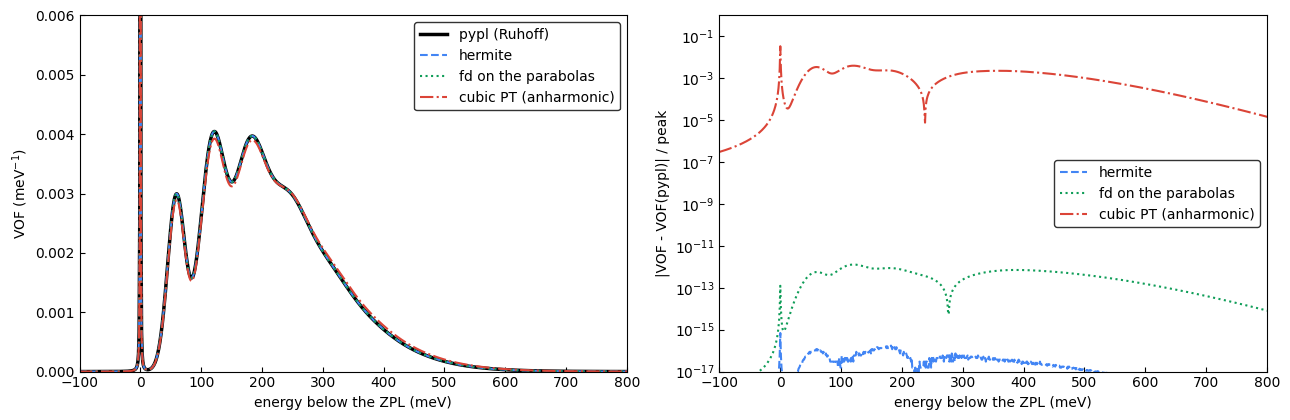

In [6]:
axis = lsp["eneaxis"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
styles = {"pypl (Ruhoff)": dict(color="k", lw=2.5), "hermite": dict(color="#4285F4", ls="--"),
          "fd on the parabolas": dict(color="#0F9D58", ls=":"), "cubic PT (anharmonic)": dict(color="#DB4437", ls="-.")}
for name, (solver, _) in results.items():
    axes[0].plot(axis, solver.fc_lineshape, label=name, **styles[name])
    if name != "pypl (Ruhoff)":
        axes[1].semilogy(axis, np.abs(solver.fc_lineshape - ref.fc_lineshape) / peak + 1e-18, label=name, **styles[name])
axes[0].set_ylim(0, 0.006)
axes[0].set_ylabel(r"VOF (meV$^{-1}$)")
axes[1].set_ylabel("|VOF - VOF(pypl)| / peak")
axes[1].set_ylim(1e-17, 1)
for ax in axes:
    ax.set_xlim(-100, 800)
    ax.set_xlabel("energy below the ZPL (meV)")
    ax.legend(fontsize=10, edgecolor="black")
    ax.tick_params(direction="in")
plt.tight_layout()
plt.show()

## 4. Comparing potential fits

The finite-difference route accepts any potential, so the next question is which fit of the computed images to use (GS: DFT, ES: $\Delta$SCF, both PBE).
`config_coord_1d_potential` provides:

| fit | call | notes |
| --- | --- | --- |
| parabola | `fit_parabola(index)` | minimum fixed at `q0`; a few images near the minimum; the harmonic reference |
| polynomial | `fit_polynomial(degree, index)` | bound only for even degree with a positive leading coefficient |
| Morse | `fit_morse(index)` | both signs of the anharmonicity tried |
| cubic | `fit_cubic(index, curvature)` | for perturbation theory; unbounded beyond its turnover |
| spline | `fit_spline(index, order, bc, smoothing, tails)` | through every image; `order` 2-5, `bc` natural / not-a-knot / clamped, `tails` harmonic or smooth ($C^2$) |

Every fit records `kind`, `params`, `index` (the images used) and `bounded` (whether it has bound states), and
`describe()` prints all of it. **Always check `bounded` before solving**: a polynomial with a negative leading coefficient
goes to $-\infty$, and the finite-difference states then collapse into the walls of the box.

In [7]:
def make_fits(state):
    q, e = images[state]
    c = center[state]
    fits = {"parabola": parabola[state]}
    for label, method, kwargs in (
        ("poly2", "fit_polynomial", dict(degree=2)),
        ("poly4", "fit_polynomial", dict(degree=4)),
        ("Morse", "fit_morse", {}),
        ("spline (natural, harmonic tails)", "fit_spline", dict(order=3, bc="natural")),
        ("spline (not-a-knot, smooth tails)", "fit_spline", dict(order=3, bc="not-a-knot", tails="smooth")),
        ("spline (quintic, clamped)", "fit_spline", dict(order=5, bc="clamped")),
    ):
        pot = config_coord_1d_potential(q, e, q0=c)
        getattr(pot, method)(**kwargs)
        fits[label] = pot
    return fits


fits = {s: make_fits(s) for s in ("gs", "es")}
print("%-36s %10s %12s %12s %12s" % ("fit", "bounded", "rms GS (meV)", "rms ES (meV)", "hw GS (meV)"))
for label in fits["gs"]:
    g, x = fits["gs"][label], fits["es"][label]
    print("%-36s %10s %12.3f %12.3f %12.2f" % (label, g.bounded and x.bounded, 1e3 * g.rms(), 1e3 * x.rms(),
                                                g.phonon_energy() if g.bounded else float("nan")))
print("\nGS poly4: " + fits["gs"]["poly4"].describe())

fit                                     bounded rms GS (meV) rms ES (meV)  hw GS (meV)
parabola                                   True        2.114        0.842        59.09
poly2                                      True        0.152        0.077        59.70
poly4                                     False        0.052        0.042          nan
Morse                                      True        0.110        0.044        59.28
spline (natural, harmonic tails)           True        0.000        0.000        56.42
spline (not-a-knot, smooth tails)          True        0.000        0.000        58.32
spline (quintic, clamped)                  True        0.000        0.000        59.11

GS poly4: degree-4 polynomial in (Q - 0.000000), coefficients (highest first) [-0.01808, 0.03027, 0.412, 8.473e-05, 4.138e-05]; fitted to samples 1-15 of 15 (Q = -0.139..0.835); rms residual 5.16e-05 eV; UNBOUNDED: leading coefficient p_4 = -0.0181 < 0, so V -> -inf as |Q| -> inf


The rms column is the residual over **all** images: the parabola only fits its own few images, splines pass through
every image (0), and the quartic is flagged unbounded (its leading coefficient comes out negative, because the images
span too short a range to fix it). The fits only differ much *outside* the sampled range, where the higher vibrational
levels live, so it is worth looking there:

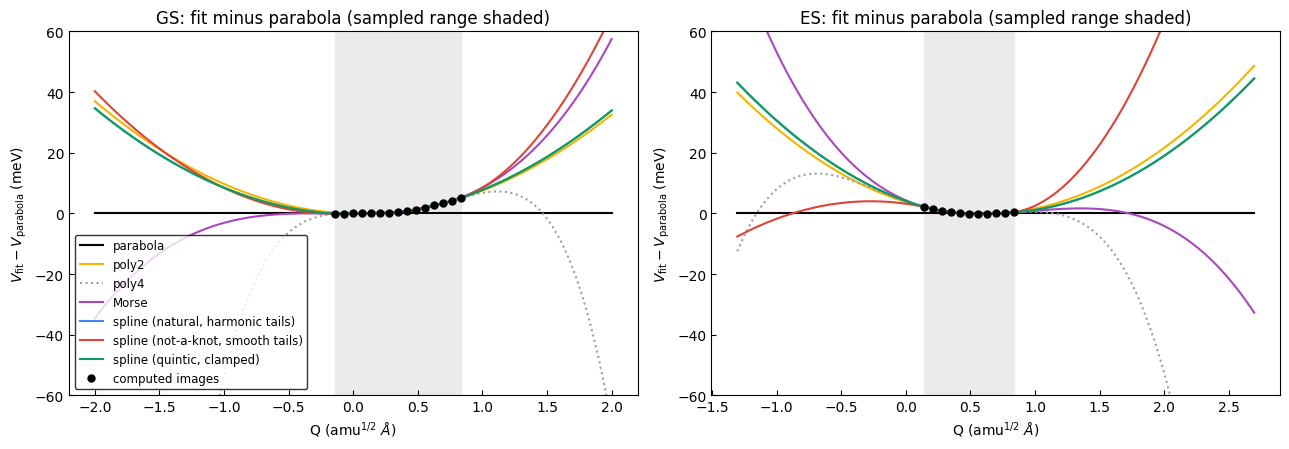

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
colors = ["k", "#F4B400", "#9E9E9E", "#AB47BC", "#4285F4", "#DB4437", "#0F9D58"]
for ax, state in zip(axes, ("gs", "es")):
    q, e = images[state]
    x = np.linspace(center[state] - 2.0, center[state] + 2.0, 800)
    for (label, pot), color in zip(fits[state].items(), colors):
        ax.plot(x, 1e3 * (pot(x) - parabola[state](x)), color=color, ls="-" if pot.bounded else ":", label=label)
    ax.plot(q, 1e3 * (e - parabola[state](q)), "o", color="k", ms=5, label="computed images")
    ax.axvspan(q.min(), q.max(), color="0.92", zorder=0)
    ax.set_ylim(-60, 60)
    ax.set_title("%s: fit minus parabola (sampled range shaded)" % state.upper())
    ax.set_xlabel(r"Q (amu$^{1/2}$ $\AA$)")
    ax.set_ylabel(r"$V_\mathrm{fit} - V_\mathrm{parabola}$ (meV)")
    ax.tick_params(direction="in")
axes[0].legend(fontsize=8.5, edgecolor="black", loc="lower left")
plt.tight_layout()
plt.show()

Now the VOF on every bounded fit. With anharmonic wells the vibrational levels are no longer a harmonic ladder, so we use
`build_fc_lsp_from_levels`, which places each line at the actual finite-difference level energies (same broadening and
Boltzmann weights as `bulid_fc_lsp`, which it equals for harmonic ladders). The reference is the harmonic VOF of
section 3.

skipped (unbounded): poly4

fit                                   max |dVOF| / peak   centroid shift (meV)  E_10 - E_0 GS
parabola                                       9.93e-13                   0.00       590.9 meV
poly2                                          4.64e-03                   2.15       597.0 meV
Morse                                          1.95e-02                   3.05       592.7 meV
spline (natural, harmonic tails)               9.09e-03                   2.55       596.7 meV
spline (not-a-knot, smooth tails)              3.21e-03                   1.58       597.2 meV
spline (quintic, clamped)                      1.00e-02                   2.58       596.7 meV
harmonic GS ladder: E_10 - E_0 = 590.9 meV


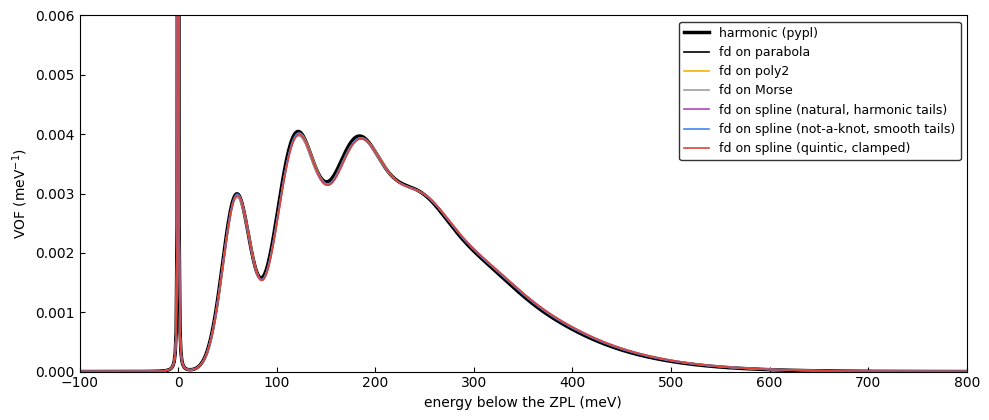

In [9]:
def centroid(lineshape):
    return np.sum(axis * lineshape) / np.sum(lineshape)


fit_vofs = {}
for label in fits["gs"]:
    if not (fits["gs"][label].bounded and fits["es"][label].bounded):
        print("skipped (unbounded): %s" % label)
        continue
    solver = config_coord_1d_vof_solver(w_es, w_gs, delta_q)
    with contextlib.redirect_stdout(io.StringIO()):
        solver.compute_franck_condon_integrals_fd(ni, nf, fits["es"][label], fits["gs"][label], q_i=delta_q, q_f=0.0)
        solver.build_fc_lsp_from_levels(**lsp)
    fit_vofs[label] = solver

print("\n%-36s %18s %22s %14s" % ("fit", "max |dVOF| / peak", "centroid shift (meV)", "E_10 - E_0 GS"))
for label, solver in fit_vofs.items():
    print("%-36s %18.2e %22.2f %11.1f meV" % (label, np.max(np.abs(solver.fc_lineshape - ref.fc_lineshape)) / peak,
          centroid(solver.fc_lineshape) - centroid(ref.fc_lineshape), 1e3 * (solver.fd_energies_f[10] - solver.fd_energies_f[0])))
print("harmonic GS ladder: E_10 - E_0 = %.1f meV" % (10 * w_gs))

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(axis, ref.fc_lineshape, color="k", lw=2.5, label="harmonic (pypl)")
for (label, solver), color in zip(fit_vofs.items(), colors):
    ax.plot(axis, solver.fc_lineshape, color=color, lw=1.2, label="fd on " + label)
ax.set_xlim(-100, 800)
ax.set_ylim(0, 0.006)
ax.set_xlabel("energy below the ZPL (meV)")
ax.set_ylabel(r"VOF (meV$^{-1}$)")
ax.legend(fontsize=9, edgecolor="black")
ax.tick_params(direction="in")
plt.tight_layout()
plt.show()

For NV$^-$ in diamond every bounded fit gives nearly the same VOF: the wells are close to harmonic, and the fd route on the
parabola itself reproduces the harmonic VOF exactly. The recommended anharmonic fit is the **not-a-knot spline with smooth
tails** (`fit_spline(order=3, bc="not-a-knot", tails="smooth")`): it passes through every image, imposes nothing at the
end images, and continues the curve with its own value, slope and curvature, so the PES is $C^2$ everywhere. For strongly
anharmonic systems the choice matters a lot (Tutorial 003: NV$^-$ in MgO).

## 5. The validation scripts

The same comparisons, with every setting recorded, figures, CSV tables and an `index.md`, come from the scripts in
`validation/`. Every script shares the VOF flags (`--temp --sigma --gamma --order-es --order-gs --ene-range --resol
--fd-fit --fd-npts ...`, see `--help`) and `--dataset nv_diamond|nv_mgo`. Results go to
`validation/outputs/<script>/<run>/`; a rerun under the same name archives the old run to `validation/outputs/_archive/`
instead of deleting it. Here they go to the temporary directory set in section 0.

### 5.1 `compare_vof.py`: PASS / FAIL against a reference method

$ python validation/compare_vof.py --reference hermite --test pypl fd   (exit 0, 16 s)
emission    PyPL (Ruhoff)      Hermite (quadrature)  1.70e-08   (49, 48)   4.87e-11            6.95e-16         3.97e-17         0.01           OK     
emission    Finite difference  Hermite (quadrature)  3.51e-09   (40, 58)   6.11e-10            1.29e-12         3.81e-13         1.09           OK     
absorption  PyPL (Ruhoff)      Hermite (quadrature)  1.37e-08   (50, 49)   3.71e-11            6.95e-16         4.46e-17         0.03           OK     
absorption  Finite difference  Hermite (quadrature)  3.51e-09   (58, 40)   6.11e-10            9.55e-13         3.37e-13         6.72           OK     

PASS: every lineshape matches the reference.

Outputs in <tmp>\compare_vof\hermite_vs_pypl-fd (see index.md)

files: ['data', 'figures', 'index.md', 'log.txt', 'settings.json'] ['fc_error_maps.png', 'vof_comparison.png']


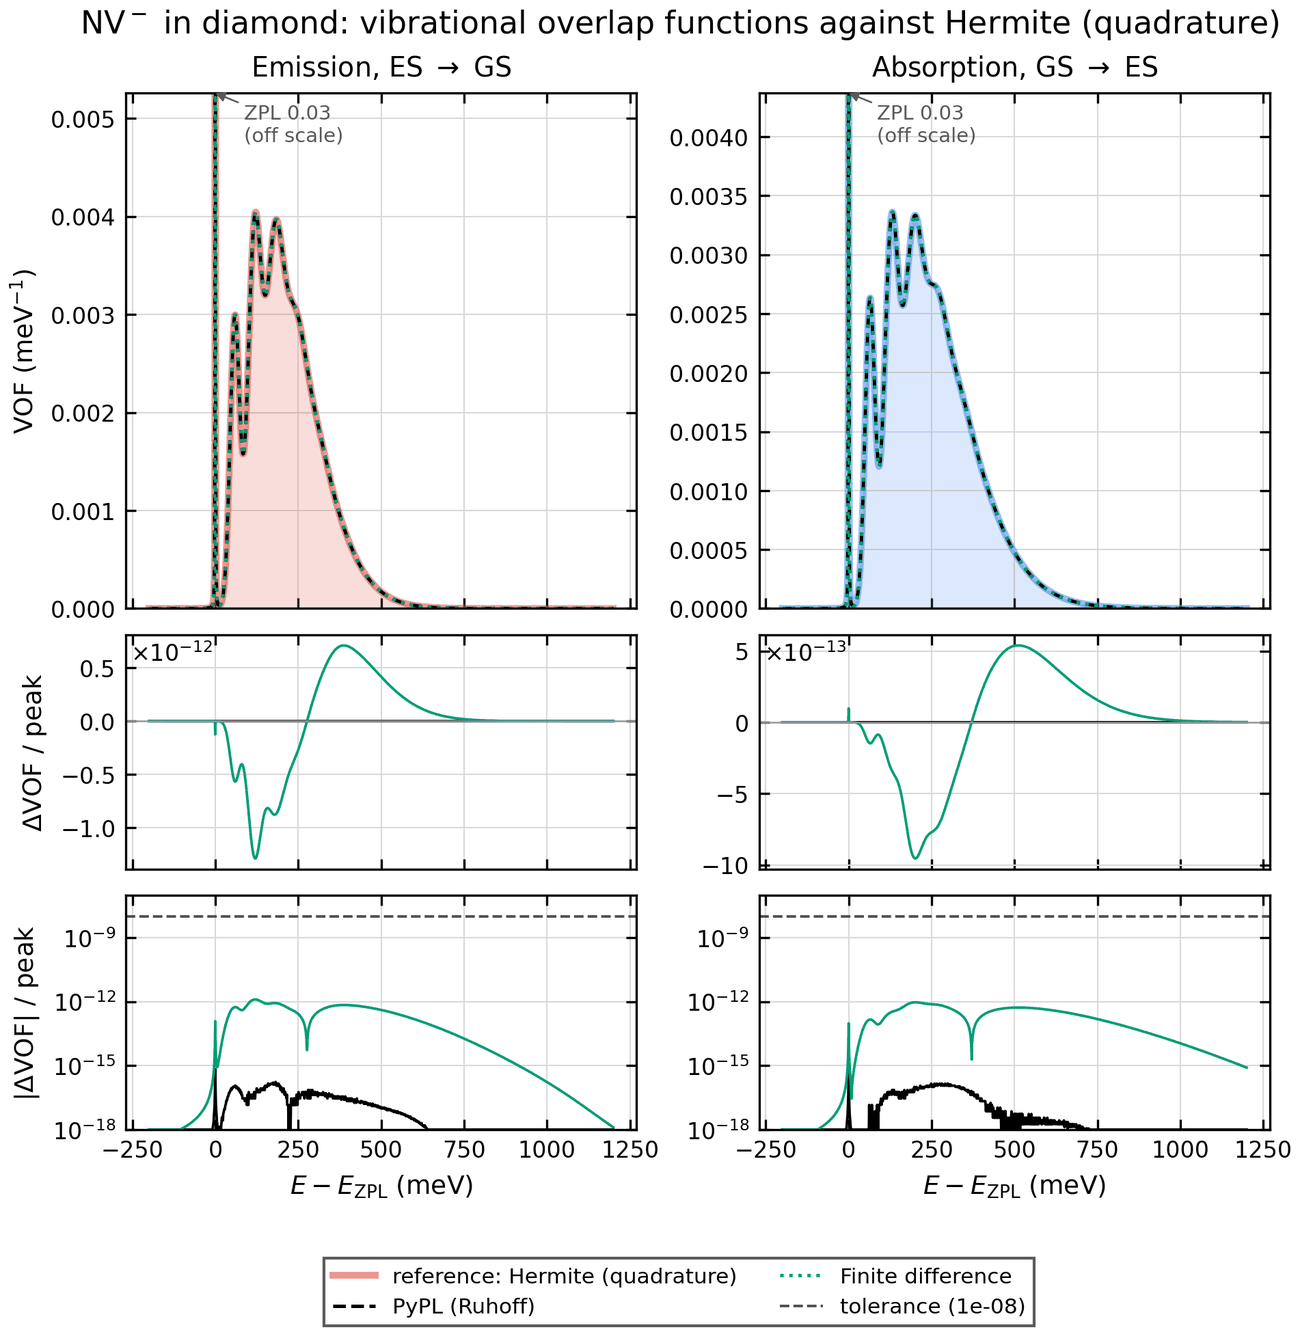

In [10]:
proc = run(["validation/compare_vof.py", "--reference", "hermite", "--test", "pypl", "fd"], tail=8)
out_dir = [line.split("Outputs in ")[1].split(" (see")[0] for line in proc.stdout.splitlines() if "Outputs in" in line][0]
out_dir = os.path.join(REPO_ROOT, out_dir) if not os.path.isabs(out_dir) else out_dir
print("\nfiles:", sorted(os.listdir(out_dir)), sorted(os.listdir(os.path.join(out_dir, "figures"))))
show(os.path.join(out_dir, "figures", "vof_comparison.png"))

Each panel of `vof_comparison.png` overlays the VOFs, then shows the signed and the log error against the reference, and
lists every setting. `index.md` in the run directory describes every file, `log.txt` has the full console output, and
`data/summary.csv` the statistics. An anharmonic fit or method is reported as `DIFFERS`/`FAIL` with a note that the
difference is physics, not error, e.g.

```bash
python validation/compare_vof.py --reference pypl --test fd --fd-fit spline3-notaknot-smooth
python validation/compare_vof.py --reference fd --fd-fit cubic --test cubic   # PT against the exact cubic
```

Fit specs for `--fd-fit`: `parabola`, `polyN`, `morse`, `cubic`, and `spline[K][-natural|-notaknot|-clamped|-sRMS][-smooth]`
(e.g. `spline3-notaknot-smooth`, `spline5-clamped`, `spline3-s0.05` for a smoothing spline with 0.05 meV rms).

### 5.2 `plot_ccd_wavefunctions.py`: the CCD, the vibrational states and the VOF

Here the finite-difference states on the smooth not-a-knot spline, with the VOF of PyPL and of finite differences
(the same flags work with `--dataset nv_mgo`):

$ python validation/plot_ccd_wavefunctions.py --wf-method fd --vof-method pypl fd --fd-fit spline3-notaknot-smooth --n-levels 4   (exit 0, 16 s)
    Finite difference [cubic spline (not-a-knot, smooth C2 tails)] vs PyPL (Ruhoff): max |difference| / peak = 1.86e-03

Outputs in <tmp>\plot_ccd_wavefunctions\wf-fd_vof-pypl-fd_fit-spline3-notaknot-smooth (see index.md)


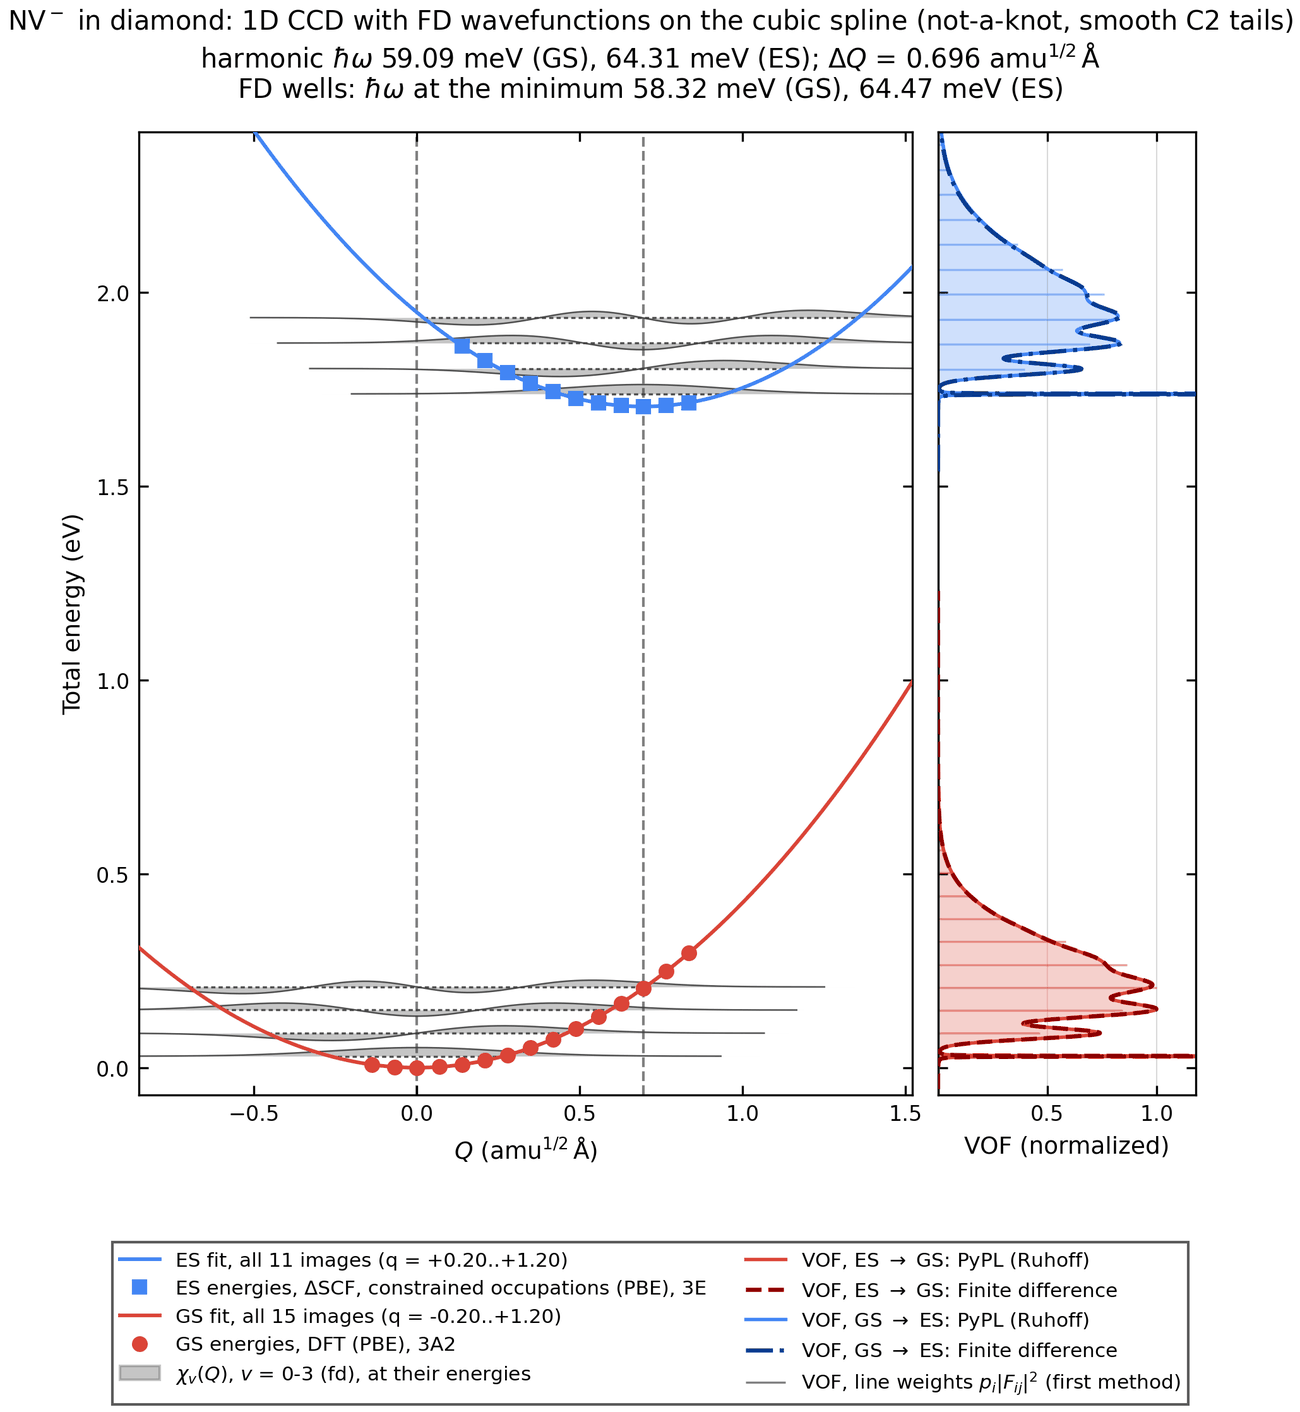

In [11]:
proc = run(["validation/plot_ccd_wavefunctions.py", "--wf-method", "fd", "--vof-method", "pypl", "fd",
            "--fd-fit", "spline3-notaknot-smooth", "--n-levels", "4"], tail=3)
out_dir = [line.split("Outputs in ")[1].split(" (see")[0] for line in proc.stdout.splitlines() if "Outputs in" in line][0]
out_dir = os.path.join(REPO_ROOT, out_dir) if not os.path.isabs(out_dir) else out_dir
show(os.path.join(out_dir, "ccd_wavefunctions.png"))

### 5.3 `vof_report.py` and `run_all.py`: the complete comparison

`vof_report.py` writes a seven-section report (fits, finite-difference grid and convergence, wavefunctions, $F_{ij}$
error maps, VOF by method, VOF by fit, cubic perturbation theory), about 8 minutes:

```bash
python validation/vof_report.py --fits parabola spline3-notaknot-smooth morse poly2 --tag my-fits
```

`run_all.py` runs **every** method, fit and variant from one TOML configuration (`validation/run_all.toml` for NV$^-$ in
diamond, every key commented; `validation/run_all_nv_mgo.toml` for NV$^-$ in MgO) and writes one `index.md` with the
comparison table and a link to every step. `--set section.key=value` overrides a key, `--only` selects step groups,
`--dry-run` lists the commands without running them:

In [12]:
proc = run(["validation/run_all.py", "--config", "validation/run_all_nv_mgo.toml", "--only", "compare", "--dry-run"], tail=14)

$ python validation/run_all.py --config validation/run_all_nv_mgo.toml --only compare --dry-run   (exit 0, 1 s)
[ 5] compare  fd on polynomial deg. 2 vs hermite
     python validation/compare_vof.py --reference hermite --test fd --dataset nv_mgo --temp 5.0 --sigma 20.0 --gamma 0.3 --no-zpl --order-es 160 --order-gs 100 --ene-range -500.0 10000.0 --resol 2101 --line-positions harmonic --npts 100001 --hermite-margin 6.0 --fd-stencil 5 --fd-margin 2.0 --fd-fit poly2 --fd-npts 40001 --cubic-warn 0.1 --dpi 300 --fig-format png --font-size 9.0 --tol-fc 1e-07 --tol-vof 1e-08
[ 6] compare  fd on polynomial deg. 4 vs hermite
     python validation/compare_vof.py --reference hermite --test fd --dataset nv_mgo --temp 5.0 --sigma 20.0 --gamma 0.3 --no-zpl --order-es 160 --order-gs 100 --ene-range -500.0 10000.0 --resol 2101 --line-positions harmonic --npts 100001 --hermite-margin 6.0 --fd-stencil 5 --fd-margin 2.0 --fd-fit poly4 --fd-npts 40001 --cubic-warn 0.1 --dpi 300 --fig-format png --font-si

A full suite takes 15-20 minutes:

```bash
python validation/run_all.py                                            # NV- in diamond -> validation/outputs/suite/default/
python validation/run_all.py --config validation/run_all_nv_mgo.toml    # NV- in MgO     -> validation/outputs/suite/nv_mgo/
python validation/run_all.py --set physics.temp=300 --name 300K         # a variant under its own name
```

## 6. Results of the full suites

`run_all.py` was run on both datasets with the configurations shipped in `validation/`:

```bash
python validation/run_all.py                                            # NV- in diamond -> validation/outputs/suite/default/
python validation/run_all.py --config validation/run_all_nv_mgo.toml    # NV- in MgO     -> validation/outputs/suite/nv_mgo/
```

The cells below read the results the suites wrote (each suite's `index.md`, the CSV tables and the figures of its
report), so this section always shows the latest run. Rerunning a suite updates it; the previous run is archived in
`validation/outputs/_archive/`.

In [13]:
import csv
import re

from IPython.display import Markdown

SUITES = os.path.join(REPO_ROOT, "validation", "outputs", "suite")


def suite_status(name):
    # Status counts and the method-comparison table, read from the suite's index.md.
    text = open(os.path.join(SUITES, name, "index.md"), encoding="utf-8").read()
    header = text.splitlines()[0].lstrip("# ")
    started = re.search(r"Started (\S+), (\d+) steps in (\d+) s", text)
    statuses = re.findall(r"^\| \d+ \| [^|]+ \| ([A-Z]+)", text, flags=re.M)
    counts = {k: statuses.count(k) for k in ("PASS", "OK", "DIFFERS", "FAIL", "ERROR")}
    table = text.split("## Method comparison", 1)[1].split("## Steps", 1)[0].strip().splitlines()
    table = [line for line in table if line.startswith("|")]
    return header, started, counts, table


def read_csv(path):
    with open(path, encoding="utf-8") as f:
        return list(csv.DictReader(f))


def report(name, *parts):
    return os.path.join(SUITES, name, "vof_report", "default", *parts)


header, started, counts, table = suite_status("default")
print(header)
print("run %s: %s steps in %s s" % started.groups())
print("PASS %(PASS)d, OK %(OK)d, DIFFERS (expected) %(DIFFERS)d, FAIL %(FAIL)d, ERROR %(ERROR)d" % counts)
display(Markdown("\n".join(table)))

PyPL 1D CCD test suite: default (NV- in diamond)
run 2026-10-16T21:05:42: 30 steps in 432 s
PASS 3, OK 14, DIFFERS (expected) 13, FAIL 0, ERROR 0


| kind | method | compared with | max dVOF / peak | max dF_ij | F_ij time (s) | verdict |
| --- | --- | --- | --- | --- | --- | --- |
| like for like | Hermite (quadrature) | PyPL (Ruhoff) | 6.95e-16 | 1.70e-08 | 0.53 | OK |
| like for like | Finite difference | PyPL (Ruhoff) | 1.29e-12 | 1.80e-08 | 2.38 | OK |
| PT vs exact cubic | Hermite + cubic PT [cubic (a fitted, all images)] | Finite difference [cubic (a fitted, all images)] | 2.71e-03 | 9.60e-01 | 0.80 | differs (expected) |
| PT vs exact cubic | Hermite + cubic PT [cubic (a fixed, all images)] | Finite difference [cubic (a fixed, all images)] | 3.25e-04 | 1.16e+00 | 0.81 | differs (expected) |
| anharmonic vs harmonic | Finite difference [cubic spline (not-a-knot, smooth C2 tails)] | PyPL (Ruhoff) | 1.86e-03 | 1.46e-01 | 1.09 | differs (expected) |
| anharmonic vs harmonic | Finite difference [polynomial deg. 2] | PyPL (Ruhoff) | 2.42e-03 | 3.36e-03 | 1.50 | differs (expected) |
| anharmonic vs harmonic | Finite difference [Morse] | PyPL (Ruhoff) | 1.95e-02 | 4.01e-01 | 4.01 | differs (expected) |
| anharmonic vs harmonic | Finite difference [cubic spline (natural)] | PyPL (Ruhoff) | 2.08e-02 | 1.79e-02 | 0.95 | differs (expected) |
| anharmonic vs harmonic | Finite difference [quintic spline (clamped)] | PyPL (Ruhoff) | 2.16e-02 | 1.79e-02 | 1.77 | differs (expected) |
| anharmonic vs harmonic | Finite difference [quartic spline (not-a-knot)] | PyPL (Ruhoff) | 2.18e-02 | 1.80e-02 | 0.96 | differs (expected) |
| anharmonic vs harmonic | Finite difference [cubic smoothing spline (rms 0.05 meV)] | PyPL (Ruhoff) | 2.21e-02 | 1.81e-02 | 0.95 | differs (expected) |
| anharmonic vs harmonic | Hermite + cubic PT [cubic (a fitted, all images)] | PyPL (Ruhoff) | 3.28e-02 | 9.81e-01 | 0.78 | differs (expected) |
| anharmonic vs harmonic | Finite difference [cubic (a fixed, all images)] | PyPL (Ruhoff) | 3.38e-02 | 4.89e-01 | 1.66 | differs (expected) |
| anharmonic vs harmonic | Hermite + cubic PT [cubic (a fixed, all images)] | PyPL (Ruhoff) | 3.41e-02 | 1.18e+00 | 0.85 | differs (expected) |
| anharmonic vs harmonic | Finite difference [polynomial deg. 6] | PyPL (Ruhoff) | 6.96e-02 | 7.06e-01 | 0.71 | differs (expected) |

### 6.1 NV$^-$ in diamond

**Status.** Every like-for-like step passed and nothing errored; the steps reported as DIFFERS compare an anharmonic fit
or the cubic correction with the harmonic reference, where a difference is the expected physics. The table lists them
by kind: *like for like* (must agree within the tolerances), *PT vs exact cubic* (the error of first-order perturbation
theory) and *anharmonic vs harmonic* (the size of each fit's effect on the VOF), smallest first.

**Like for like.** Section 05 of the report overlays the three harmonic routes. The Hermite quadrature agrees with
PyPL's recurrences to machine precision in the VOF; the finite-difference route to $\sim 10^{-12}$ of the peak. The
$\sim 2\times10^{-8}$ in $F_{ij}$ is the float64 drift of the recurrence at the highest levels.

emission   Hermite quadrature     max |dF_ij| = 1.70e-08   max |dVOF|/peak = 6.95e-16   OK
emission   FD                     max |dF_ij| = 1.80e-08   max |dVOF|/peak = 1.28e-12   OK
absorption Hermite quadrature     max |dF_ij| = 1.37e-08   max |dVOF|/peak = 6.95e-16   OK
absorption FD                     max |dF_ij| = 1.51e-08   max |dVOF|/peak = 9.52e-13   OK


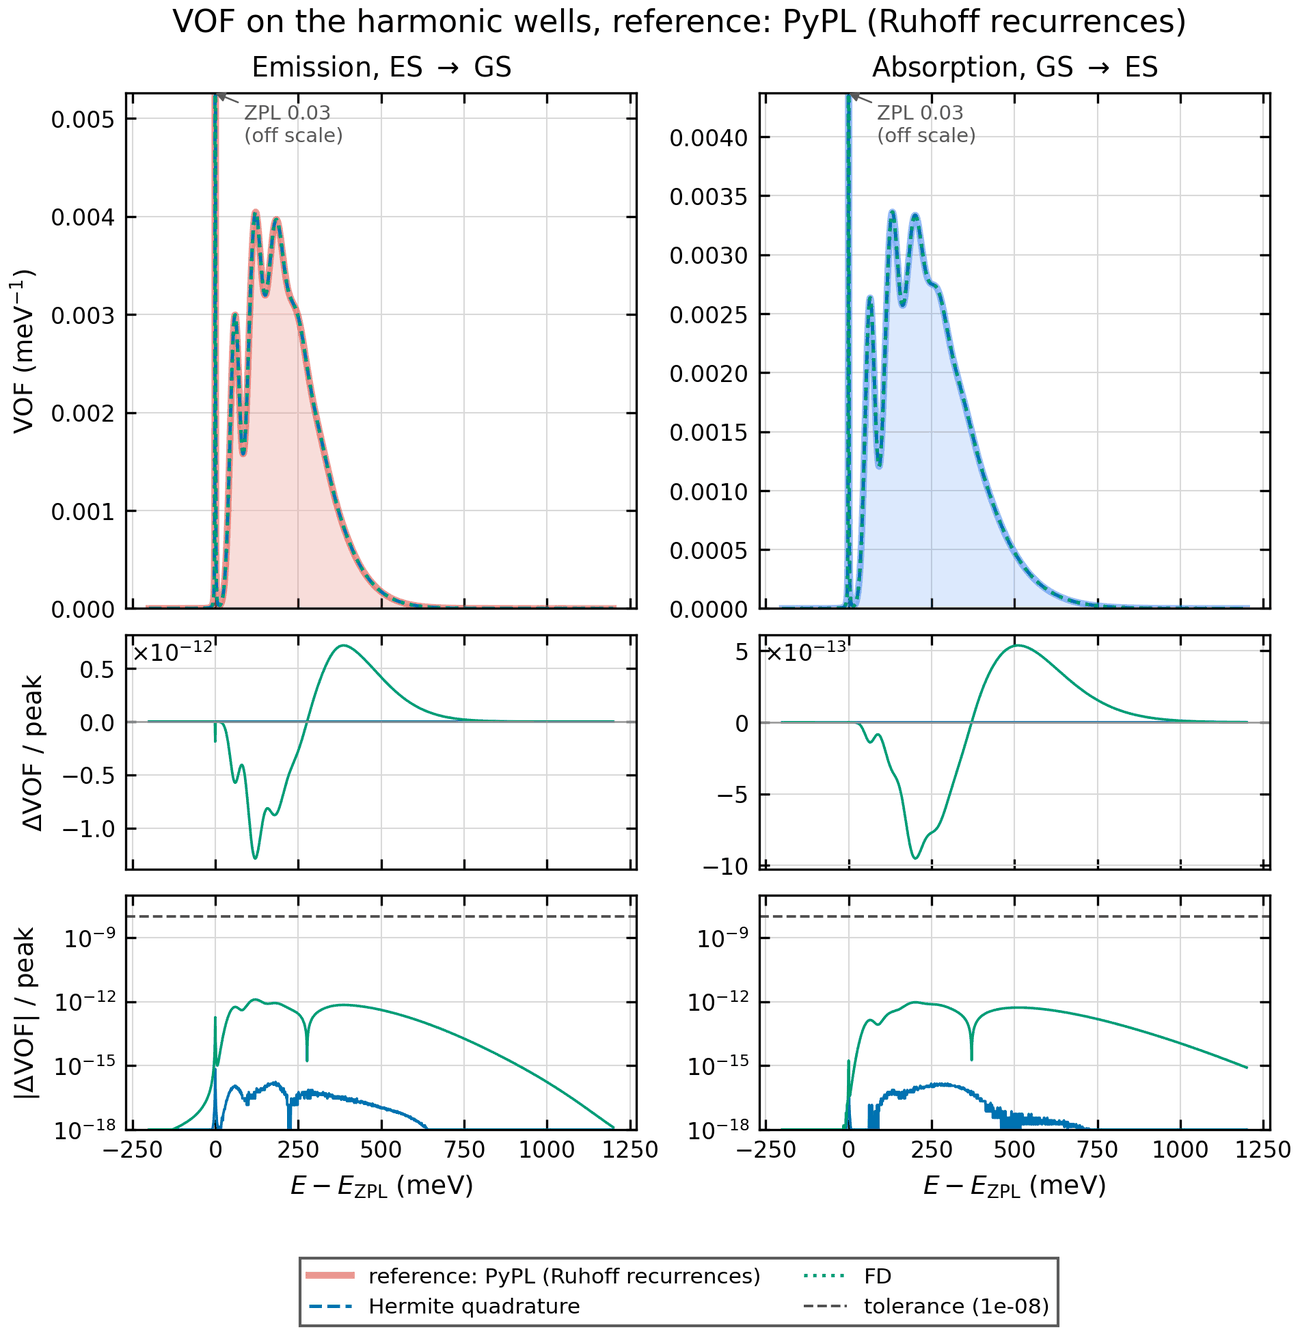

In [14]:
for row in read_csv(report("default", "05_vof_methods", "summary.csv")):
    print("%-10s %-22s max |dF_ij| = %.2e   max |dVOF|/peak = %.2e   %s"
          % (row["direction"], row["test"], float(row["fc_max"]), float(row["vof_max"]), row["verdict"]))
show(report("default", "05_vof_methods", "vof_methods.png"))

**Convergence of the finite-difference solver.** Section 02 scans the grid spacing for the 3- and 5-point stencils.
The errors of $F_{ij}$ and of the level ladder fall as $h^2$ and $h^4$, the theoretical orders; the default grid
(20001 points) sits where the 5-point error is $\sim 10^{-8}$.

3-point stencil: measured order 2.00 (F_ij), 2.00 (ladder)
5-point stencil: measured order 4.00 (F_ij), 4.00 (ladder)


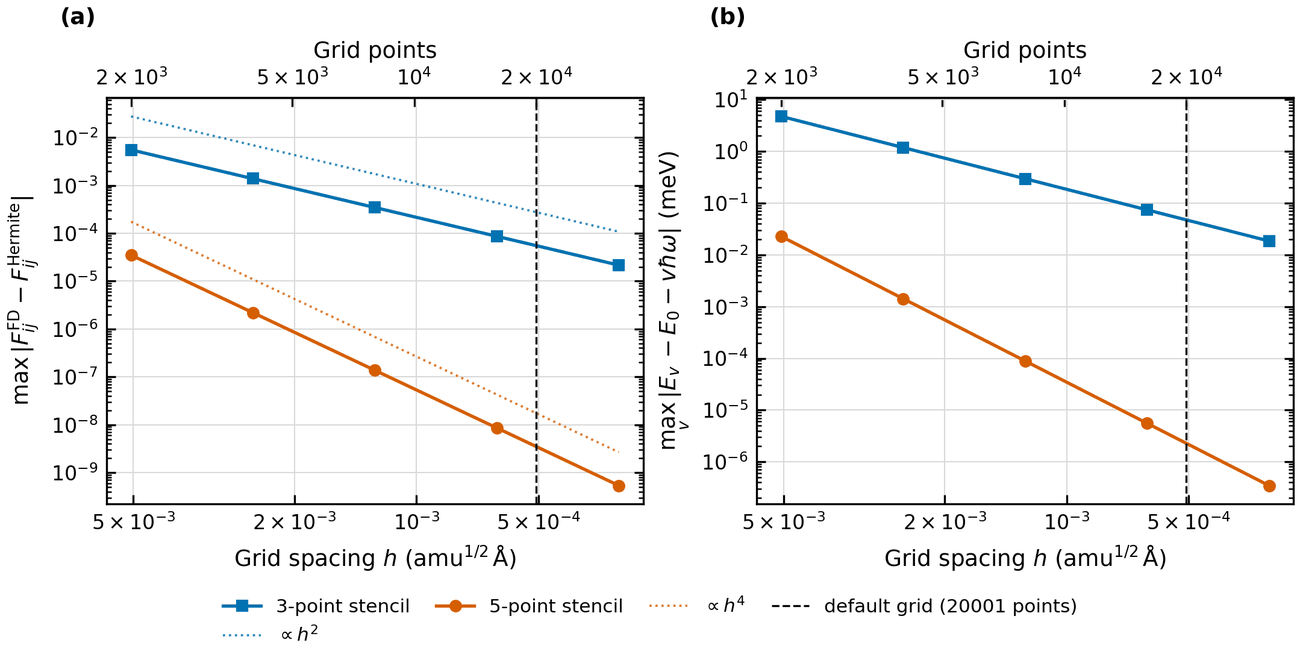

In [15]:
rows = read_csv(report("default", "02_fd_grid", "fd_convergence.csv"))
for stencil in sorted({r["stencil"] for r in rows}):
    first = next(r for r in rows if r["stencil"] == stencil)
    print("%s-point stencil: measured order %.2f (F_ij), %.2f (ladder)"
          % (stencil, float(first["slope_max_dF_vs_hermite"]), float(first["slope_ladder_error_meV"])))
show(report("default", "02_fd_grid", "fd_convergence.png"))

**Anharmonic fits.** Section 06 compares the finite-difference VOF on the report's fits with the harmonic reference.
For this nearly harmonic system every physical fit changes the VOF by at most about 2 % of its peak and its centroid by
about 2 meV; the sextic polynomial changes it most, because its extrapolated walls are unphysical. The recommended
not-a-knot spline with smooth tails is not in the report's list but has its own comparison step in the suite; it changes
the VOF least among the splines (see the method table above, about $2\times10^{-3}$ of the peak).

fit (emission)                                      max |dVOF|/peak centroid shift (meV)
parabola (near min.)                                       1.29e-12                 0.00
polynomial deg. 2                                          2.42e-03                 0.07
Morse                                                      1.95e-02                 2.40
cubic spline (natural)                                     2.08e-02                 2.24
quintic spline (clamped)                                   2.16e-02                 2.26
cubic spline (clamped)                                     2.17e-02                 2.26
cubic spline (not-a-knot)                                  2.18e-02                 2.26
quartic spline (not-a-knot)                                2.18e-02                 2.26
cubic smoothing spline (rms 0.05 meV)                      2.21e-02                 2.27
polynomial deg. 6                                          6.96e-02               -19.30


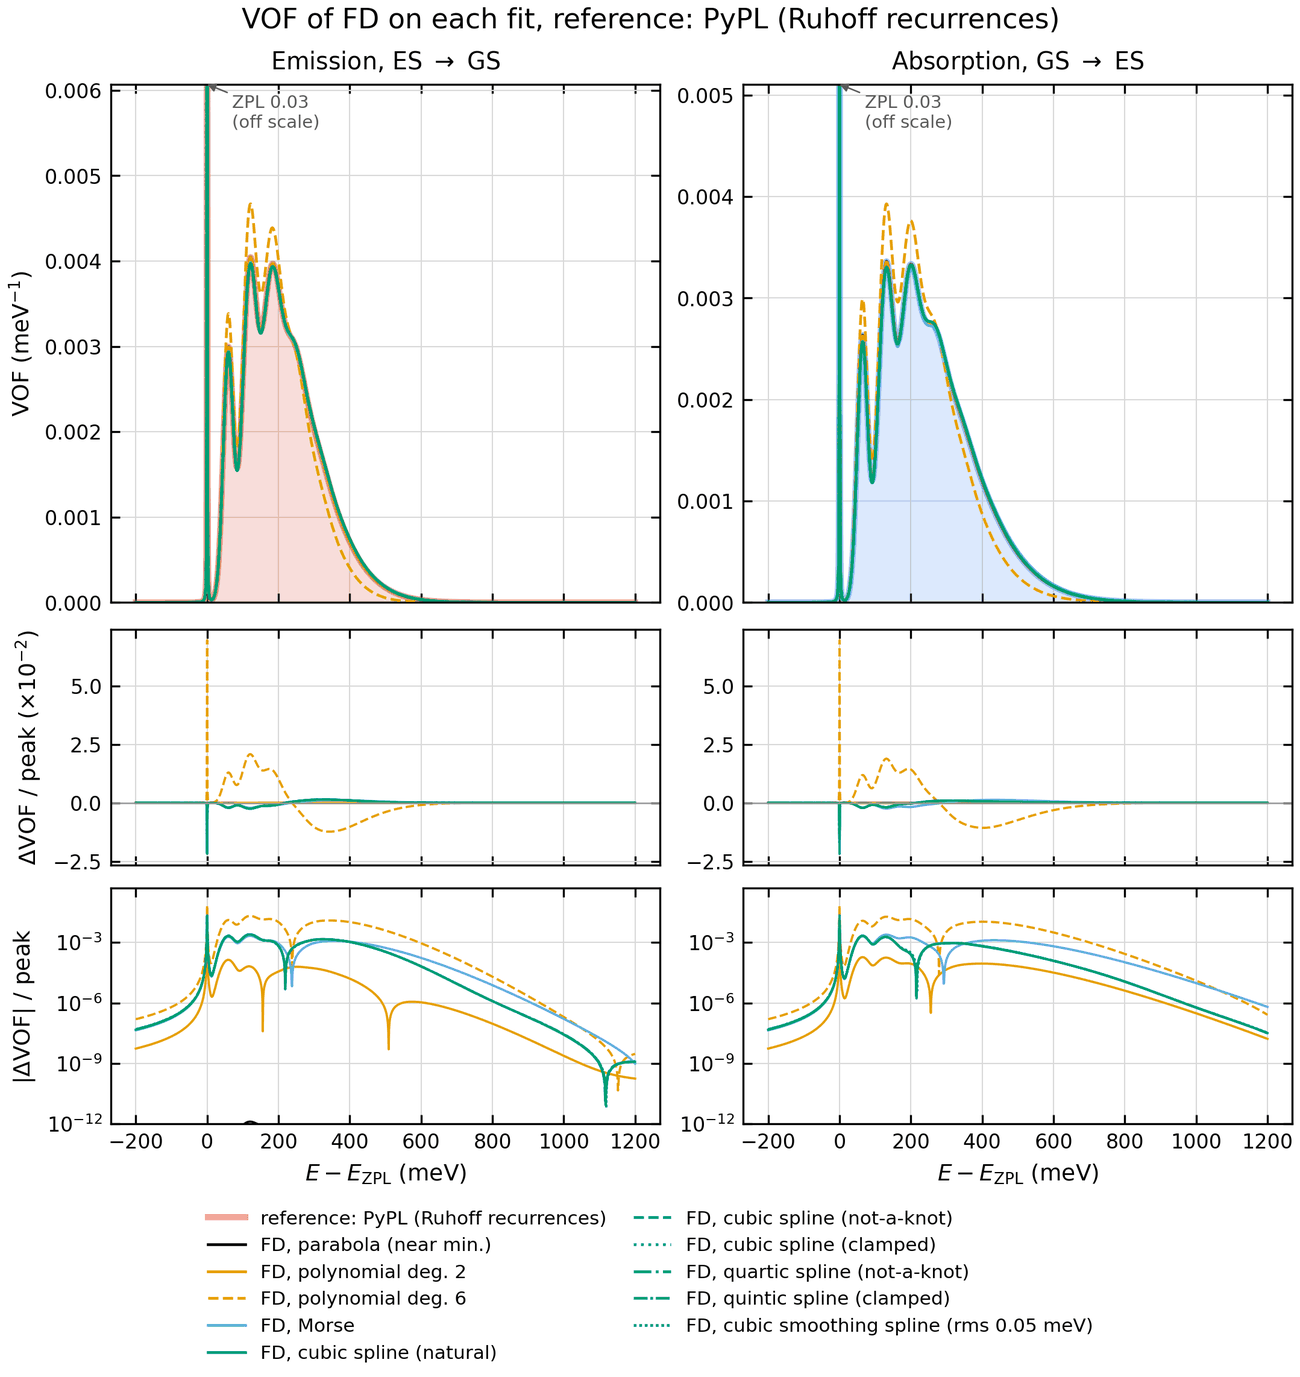

In [16]:
rows = [r for r in read_csv(report("default", "06_vof_fits", "summary.csv")) if r["direction"] == "emission"]
print("%-50s %16s %20s" % ("fit (emission)", "max |dVOF|/peak", "centroid shift (meV)"))
for r in sorted(rows, key=lambda r: float(r["vof_max"])):
    print("%-50s %16.2e %20.2f" % (r["fit"], float(r["vof_max"]), float(r["centroid_shift_mev"])))
show(report("default", "06_vof_fits", "vof_fits.png"))

**Cubic perturbation theory.** Section 07 validates the first-order correction against the exact finite-difference
solution of the same cubic: when $b$ is scaled down the error falls as $b^2$ and the effect as $b$, and the corrected
states are reliable up to the level where the mixing $3|\xi|(n+1)^{3/2}$ reaches 0.1 (Tutorial 004).

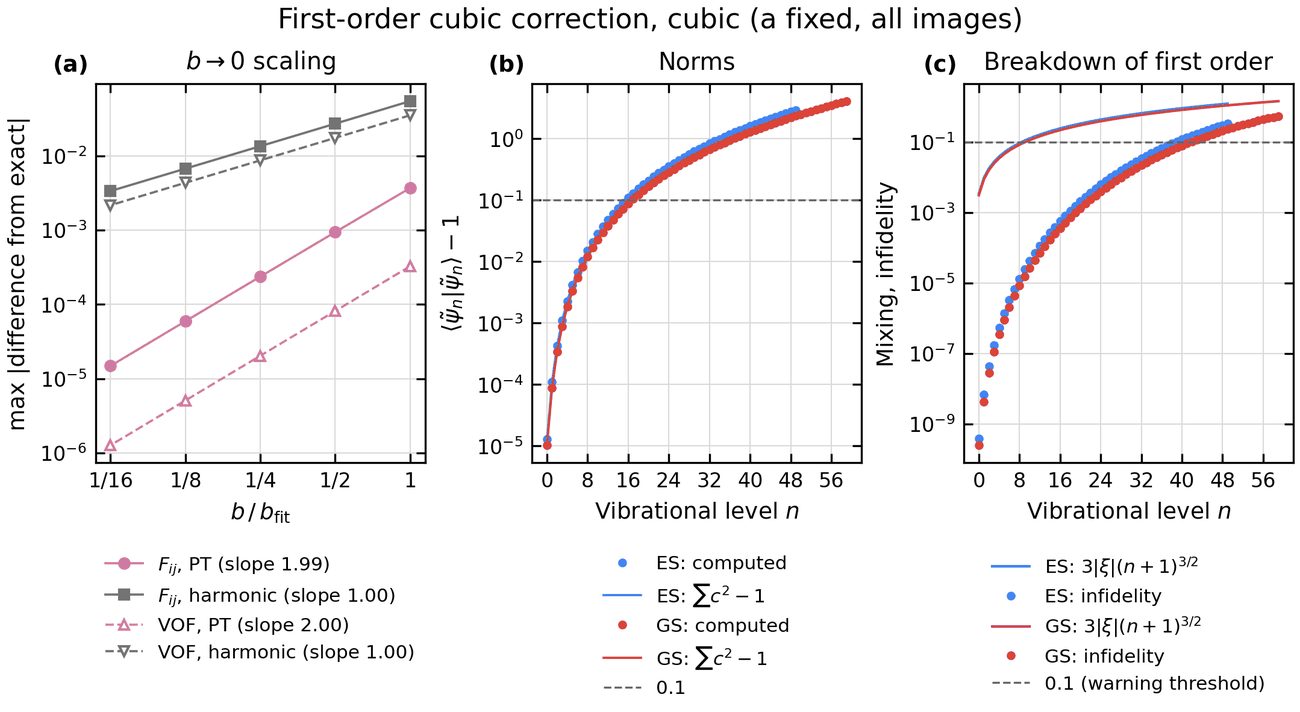

In [17]:
show(report("default", "07_cubic_perturbation", "validation.png"))

### 6.2 NV$^-$ in MgO

The MgO suite uses the settings its large Huang-Rhys factors need (160 $\times$ 100 levels, an axis to 10 eV, a
constant 20 meV broadening, 40001 finite-difference points) and **Hermite quadrature as the reference**, because PyPL's
Ruhoff recurrence is unstable in the rows $i \gtrsim 10$ at these factors (finding 6 of *Validation and testing*).
That like-for-like comparison is therefore *expected* to fail in $F_{ij}$, while the 5 K VOF, which uses only row 0,
still agrees.

In [18]:
header, started, counts, table = suite_status("nv_mgo")
print(header)
print("run %s: %s steps in %s s" % started.groups())
print("PASS %(PASS)d, OK %(OK)d, DIFFERS (expected) %(DIFFERS)d, FAIL %(FAIL)d, ERROR %(ERROR)d" % counts)
display(Markdown("\n".join(table)))

PyPL 1D CCD test suite: nv_mgo (NV- in MgO)
run 2026-10-16T21:18:38: 25 steps in 1529 s
PASS 1, OK 12, DIFFERS (expected) 10, FAIL 2, ERROR 0


| kind | method | compared with | max dVOF / peak | max dF_ij | F_ij time (s) | verdict |
| --- | --- | --- | --- | --- | --- | --- |
| like for like | PyPL (Ruhoff) | Hermite (quadrature) | 9.62e-15 | 2.68e+27 | 0.03 | FAIL |
| like for like | Finite difference | Hermite (quadrature) | 1.95e-09 | 1.03e-08 | 14.57 | OK |
| anharmonic vs harmonic | Finite difference [Morse] | Hermite (quadrature) | 3.55e+00 | 6.39e-01 | 9.26 | differs (expected) |
| anharmonic vs harmonic | Hermite + cubic PT [cubic (a fixed, images q = -0.10..+1.15)] | Hermite (quadrature) | 4.79e+00 | 1.73e+02 | 1.55 | differs (expected) |
| anharmonic vs harmonic | Finite difference [polynomial deg. 4] | Hermite (quadrature) | 6.02e+00 | 6.45e-01 | 19.91 | differs (expected) |
| anharmonic vs harmonic | Finite difference [polynomial deg. 2] | Hermite (quadrature) | 7.62e+00 | 5.61e-01 | 32.90 | differs (expected) |
| anharmonic vs harmonic | Finite difference [quintic spline (clamped)] | Hermite (quadrature) | 7.66e+00 | 7.03e-01 | 18.97 | differs (expected) |
| anharmonic vs harmonic | Finite difference [quartic spline (not-a-knot)] | Hermite (quadrature) | 8.95e+00 | 7.73e-01 | 24.34 | differs (expected) |
| anharmonic vs harmonic | Finite difference [cubic spline (not-a-knot, smooth C2 tails)] | Hermite (quadrature) | 9.58e+00 | 7.77e-01 | 15.83 | differs (expected) |
| anharmonic vs harmonic | Finite difference [cubic smoothing spline (rms 0.05 meV)] | Hermite (quadrature) | 9.58e+00 | 7.79e-01 | 14.87 | differs (expected) |
| anharmonic vs harmonic | Hermite + cubic PT [cubic (a fitted, images q = -0.10..+1.15)] | Hermite (quadrature) | 9.77e+00 | 4.76e+02 | 1.49 | differs (expected) |
| anharmonic vs harmonic | Finite difference [cubic spline (natural)] | Hermite (quadrature) | 1.05e+01 | 8.64e-01 | 14.72 | differs (expected) |

emission   PyPL (Ruhoff recurrences) max |dF_ij| = 5.10e+26   max |dVOF|/peak = 1.98e-15   FAIL
emission   FD                     max |dF_ij| = 1.03e-08   max |dVOF|/peak = 1.92e-10   OK
absorption PyPL (Ruhoff recurrences) max |dF_ij| = 2.68e+27   max |dVOF|/peak = 9.62e-15   FAIL
absorption FD                     max |dF_ij| = 1.03e-08   max |dVOF|/peak = 1.95e-09   OK


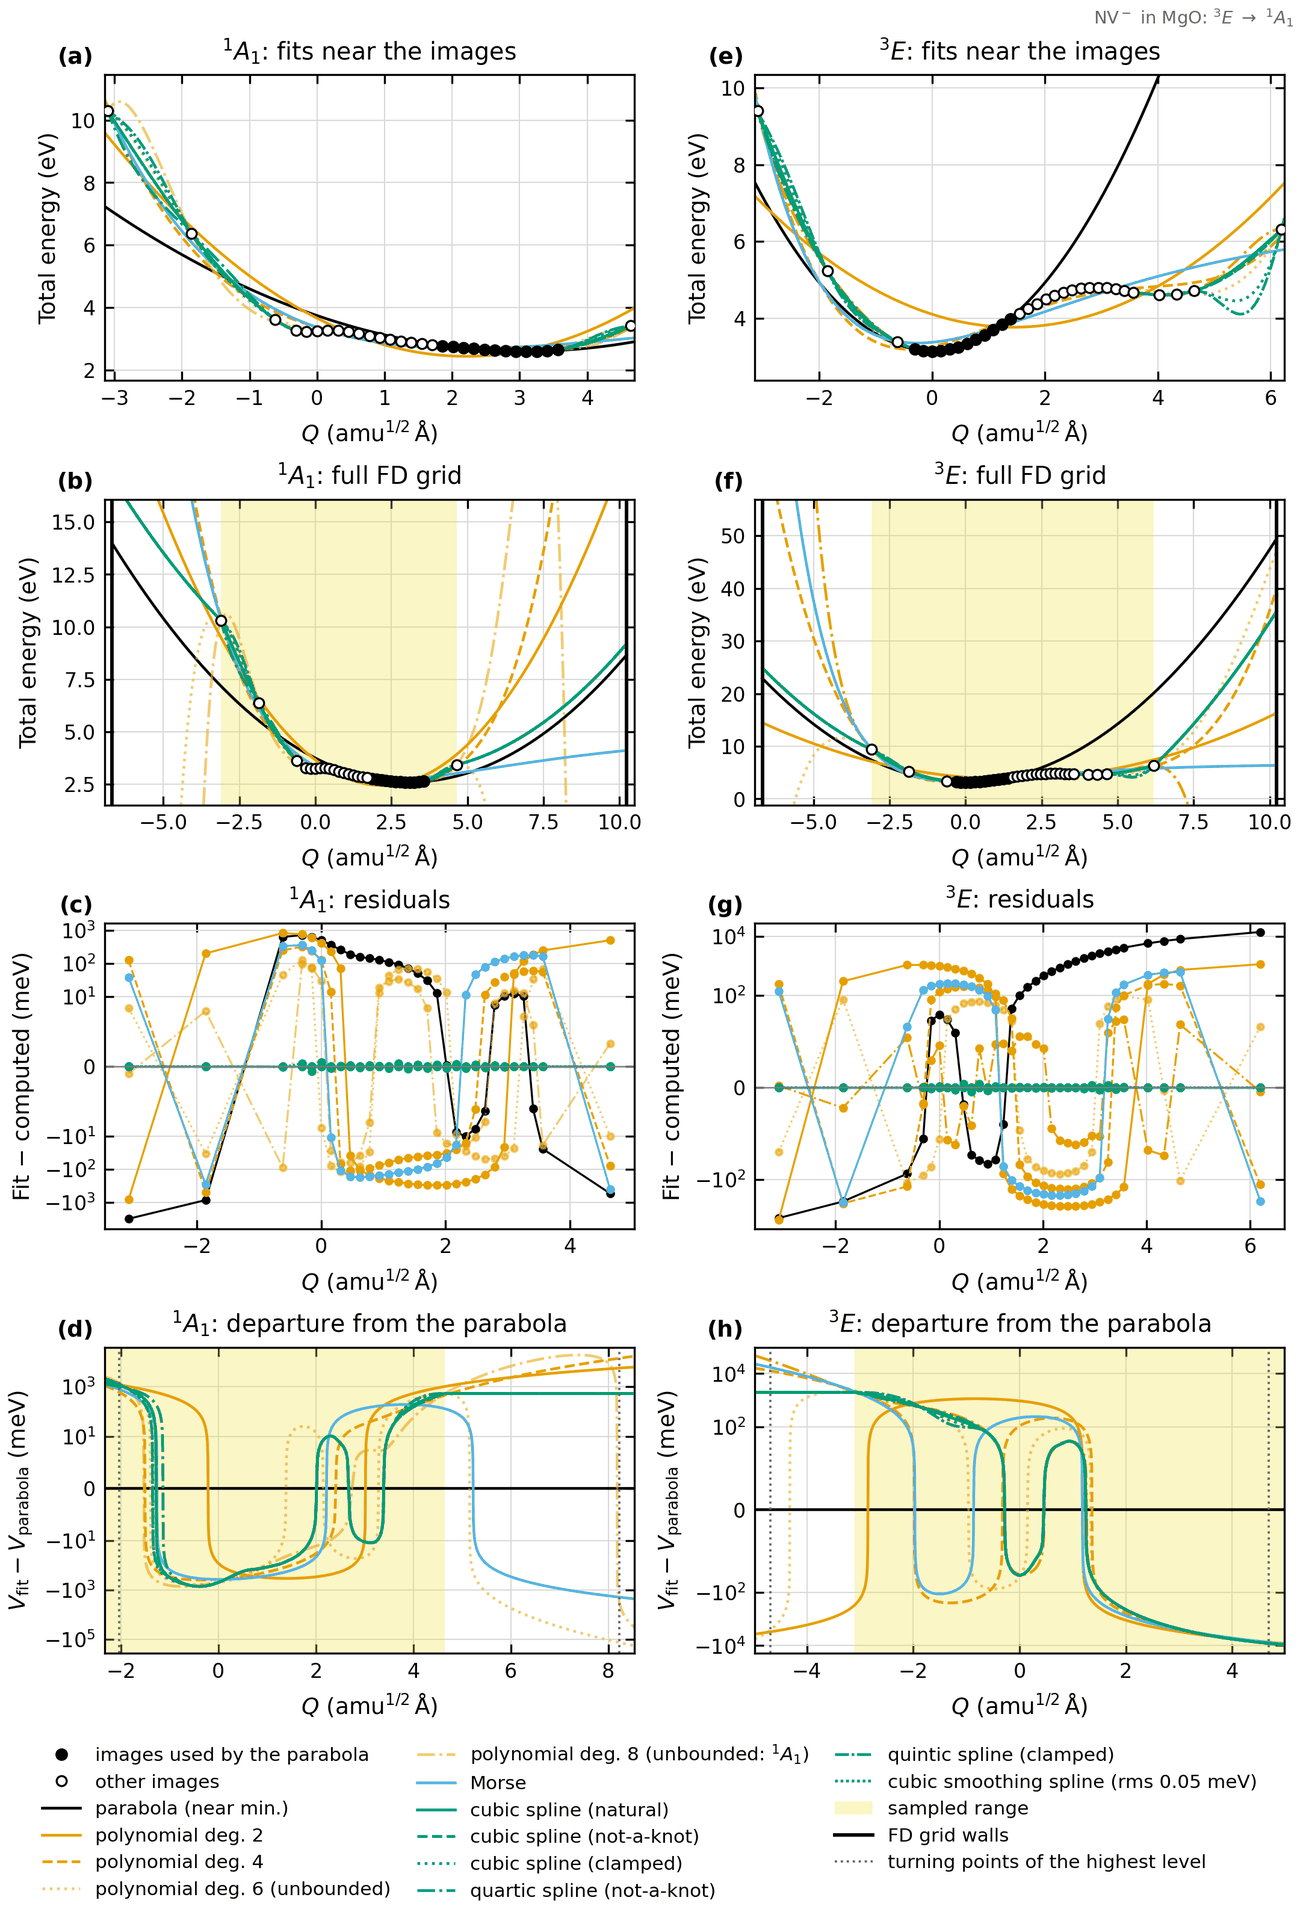

In [19]:
for row in read_csv(report("nv_mgo", "05_vof_methods", "summary.csv")):
    print("%-10s %-22s max |dF_ij| = %.2e   max |dVOF|/peak = %.2e   %s"
          % (row["direction"], row["test"], float(row["fc_max"]), float(row["vof_max"]), row["verdict"]))
show(report("nv_mgo", "01_potential_fits", "fits_overview.png"))

Here the anharmonic fits do not change the VOF by a few percent but move it by hundreds of meV: the PESs of NV$^-$ in
MgO are strongly anharmonic over $\Delta Q$, so the harmonic wells are far from the computed energies (Tutorials 003
and 004a). Section 06 shows the finite-difference VOF on every bounded fit:

fit (emission, 3E -> 1A1)                           max |dVOF|/peak centroid shift (meV)
parabola (near min.)                                       1.92e-10                  0.0
Morse                                                      4.95e-01                 42.4
polynomial deg. 4                                          7.46e-01               -186.0
polynomial deg. 2                                          2.18e+00              -1043.3
quintic spline (clamped)                                   4.82e+00               -590.5
quartic spline (not-a-knot)                                5.07e+00               -565.6
cubic spline (not-a-knot)                                  5.09e+00               -565.9
cubic smoothing spline (rms 0.05 meV)                      5.11e+00               -566.0
cubic spline (clamped)                                     5.32e+00               -584.0
cubic spline (natural)                                     5.70e+00               -572.5


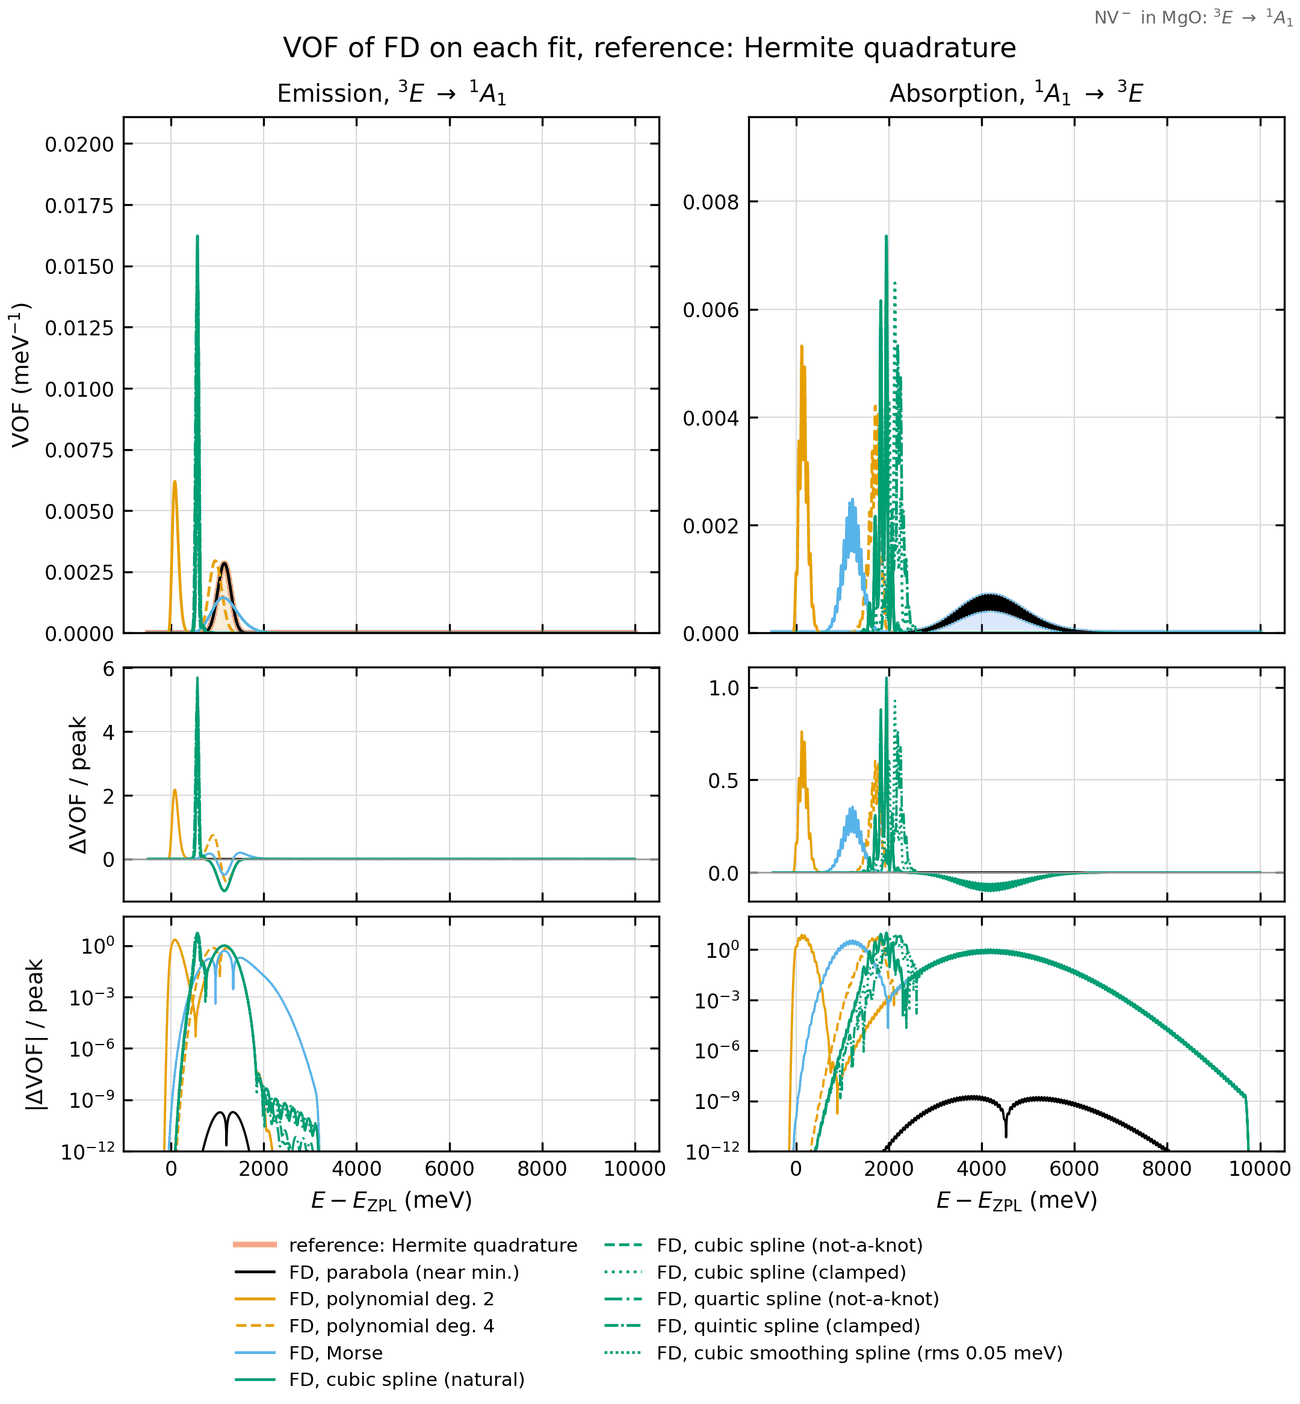

In [20]:
rows = [r for r in read_csv(report("nv_mgo", "06_vof_fits", "summary.csv")) if r["direction"] == "emission"]
print("%-50s %16s %20s" % ("fit (emission, 3E -> 1A1)", "max |dVOF|/peak", "centroid shift (meV)"))
for r in sorted(rows, key=lambda r: float(r["vof_max"])):
    print("%-50s %16.2e %20.1f" % (r["fit"], float(r["vof_max"]), float(r["centroid_shift_mev"])))
show(report("nv_mgo", "06_vof_fits", "vof_fits.png"))

## 7. Summary

- `pytest` checks the package, including that the original API still reproduces tutorials 001 and 002;
  `validation/check_1d_ccd.py` checks the physics of the 1D CCD path. Run both after any change.
- On harmonic wells, Ruhoff, Hermite and finite differences must agree (to $\sim 10^{-8}$ in $F_{ij}$ here); any anharmonic
  method or fit is then compared with them to measure the anharmonic effect, not an error.
- Check `bounded` before solving on a fit; prefer the not-a-knot spline with smooth tails for an anharmonic PES, and use
  `build_fc_lsp_from_levels` so that the line positions follow the fitted wells.
- For a full, documented comparison on your own data, the validation scripts and `run_all.py` record every setting and
  every result; `validation/METHODS.md` explains each method, its accuracy and when to use it.